In [1]:
#Cell 1: Setup and data loaders
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from src.config import CLASSES, FIG_DIR, SEED
from src.dataset import IMAGENET_MEAN, IMAGENET_STD, get_loaders


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_loader, val_loader, test_loader = get_loaders(batch_size=32)
print("Batches -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

Device: cpu
Batches -> train: 48 | val: 11 | test: 11


Batch shape: torch.Size([32, 3, 224, 224])


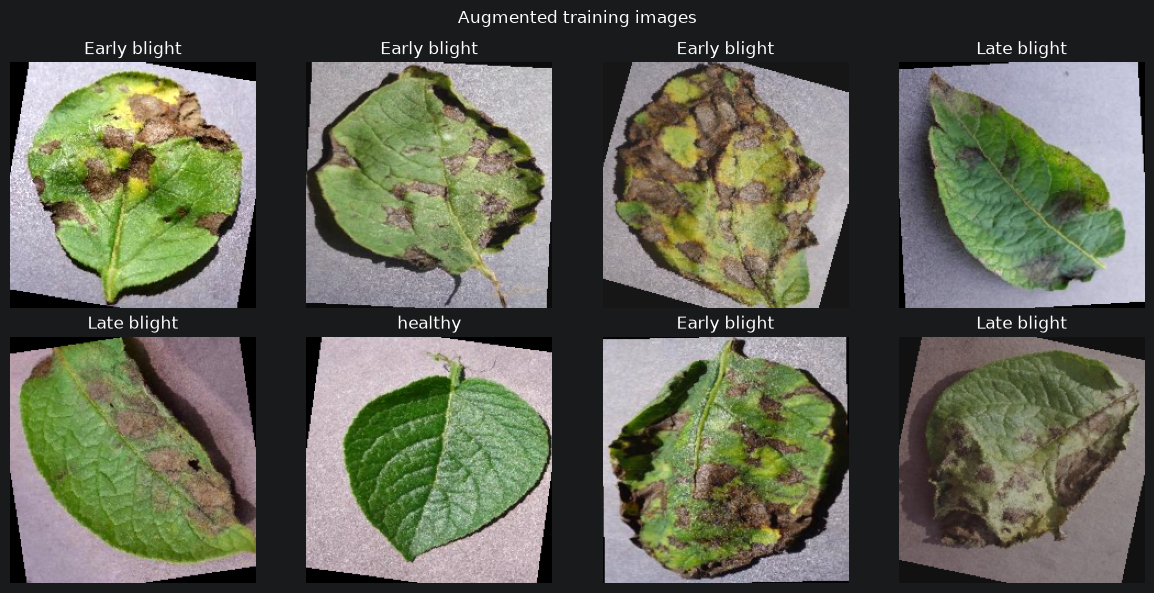

In [2]:
#Cell 2: Look at a batch of augmented images
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)

# Undo the normalization so the images display with normal colours
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
short = [c.replace("Potato___", "").replace("_", " ") for c in CLASSES]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, lbl in zip(axes.flat, images[:8], labels[:8]):
    img = (img * std + mean).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(short[lbl])
    ax.axis("off")

plt.suptitle("Augmented training images")
plt.tight_layout()
plt.savefig(FIG_DIR / "augmented_batch.png", dpi=200)
plt.show()

In [3]:
#Cell 3: The majority-class baseline
import json

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

from src.config import RESULTS_DIR, SPLITS_DIR

train_csv = pd.read_csv(SPLITS_DIR / "train.csv")
test_csv = pd.read_csv(SPLITS_DIR / "test.csv")

# "Model" that always predicts the most common training class
majority_label = train_csv["label"].mode()[0]
preds = [majority_label] * len(test_csv)

acc = accuracy_score(test_csv["label"], preds)
macro_f1 = f1_score(test_csv["label"], preds, average="macro")

print("Always predicts:", CLASSES[majority_label])
print(f"Test accuracy: {acc:.3f}")
print(f"Macro F1:      {macro_f1:.3f}")

baseline = {"model": "majority_class", "test_accuracy": acc, "test_macro_f1": macro_f1}
with open(RESULTS_DIR / "majority_baseline.json", "w") as f:
    json.dump(baseline, f, indent=2)

Always predicts: Potato___Early_blight
Test accuracy: 0.464
Macro F1:      0.211


In [4]:
#Cell 4: Create the model and test one batch
from src.models import SmallCNN, count_parameters

set_seed()
model = SmallCNN(num_classes=len(CLASSES)).to(device)
print(f"Trainable parameters: {count_parameters(model):,}")

# Quick test: pass one batch through the untrained model
with torch.no_grad():
    out = model(images.to(device))
print("Output shape:", out.shape)
print("First image's raw scores:", out[0])

Trainable parameters: 390,147
Output shape: torch.Size([32, 3])
First image's raw scores: tensor([ 0.3450,  0.7758, -0.6898])


In [6]:
#Cell 5: Train the SmallCNN
import json

import torch.nn as nn

from src.config import MODELS_DIR, RESULTS_DIR
from src.train import fit

set_seed()
model = SmallCNN(num_classes=len(CLASSES)).to(device)   # fresh, untrained model

EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = fit(
    model, train_loader, val_loader, criterion, optimizer, device,
    epochs=EPOCHS, scheduler=scheduler,
    save_path=MODELS_DIR / "small_cnn.pth",
)

with open(RESULTS_DIR / "small_cnn_history.json", "w") as f:
    json.dump(history, f, indent=2)

Epoch 01/20 | train loss 0.370 acc 0.848 | val loss 1.192 acc 0.536 f1 0.444 | 181s
Epoch 02/20 | train loss 0.309 acc 0.882 | val loss 0.193 acc 0.944 f1 0.903 | 235s
Epoch 03/20 | train loss 0.206 acc 0.917 | val loss 0.149 acc 0.947 f1 0.902 | 238s
Epoch 04/20 | train loss 0.171 acc 0.948 | val loss 0.196 acc 0.889 f1 0.708 | 254s
Epoch 05/20 | train loss 0.207 acc 0.928 | val loss 0.125 acc 0.963 f1 0.940 | 216s
Epoch 06/20 | train loss 0.179 acc 0.935 | val loss 0.164 acc 0.938 f1 0.931 | 182s
Epoch 07/20 | train loss 0.150 acc 0.943 | val loss 0.115 acc 0.975 f1 0.960 | 77s
Epoch 08/20 | train loss 0.124 acc 0.958 | val loss 0.100 acc 0.960 f1 0.919 | 91s
Epoch 09/20 | train loss 0.134 acc 0.953 | val loss 0.085 acc 0.978 f1 0.973 | 85s
Epoch 10/20 | train loss 0.127 acc 0.953 | val loss 0.075 acc 0.981 f1 0.968 | 89s
Epoch 11/20 | train loss 0.115 acc 0.965 | val loss 0.068 acc 0.981 f1 0.967 | 93s
Epoch 12/20 | train loss 0.117 acc 0.962 | val loss 0.115 acc 0.966 f1 0.953 | 93

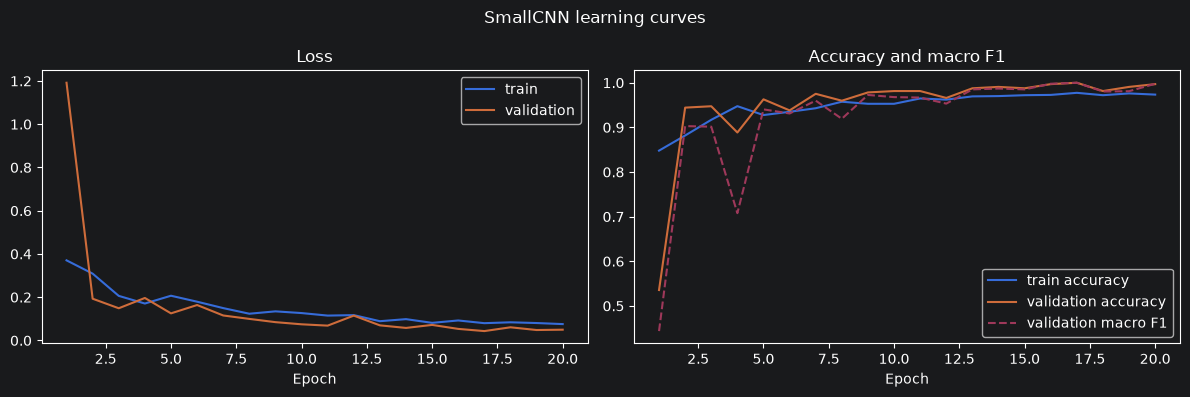

In [8]:
#Cell 6: Plot the learning curves
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs, history["train_acc"], label="train accuracy")
axes[1].plot(epochs, history["val_acc"], label="validation accuracy")
axes[1].plot(epochs, history["val_f1"], label="validation macro F1", linestyle="--")
axes[1].set_title("Accuracy and macro F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.suptitle("SmallCNN learning curves")
plt.tight_layout()
plt.savefig(FIG_DIR / "small_cnn_learning_curves.png", dpi=200)
plt.show()


In [9]:
#Cell 7: Evaluate on the test set (the real score)
from sklearn.metrics import classification_report

from src.train import evaluate

# `model` already holds the best epoch's weights (fit() reloaded them)
test_loss, test_acc, test_f1, test_preds, test_labels = evaluate(
    model, test_loader, criterion, device
)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test macro F1: {test_f1:.3f}\n")
print(classification_report(test_labels, test_preds, target_names=short, digits=3))

small_cnn_results = {
    "model": "small_cnn",
    "parameters": count_parameters(model),
    "test_accuracy": test_acc,
    "test_macro_f1": test_f1,
    "test_preds": test_preds,
    "test_labels": test_labels,
}
with open(RESULTS_DIR / "small_cnn_test_results.json", "w") as f:
    json.dump(small_cnn_results, f, indent=2)

Test accuracy: 0.985
Test macro F1: 0.977

              precision    recall  f1-score   support

Early blight      0.987     0.993     0.990       150
 Late blight      0.993     0.973     0.983       150
     healthy      0.920     1.000     0.958        23

    accuracy                          0.985       323
   macro avg      0.967     0.989     0.977       323
weighted avg      0.985     0.985     0.985       323

